# E09 Single neuron simulation

In [ ]:
%pip install brian2 matplotlib

In [2]:
# Imports/preparations for later
from brian2 import *
prefs.codegen.target = 'numpy'  # switch off code generation
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## LIF model: simulations and analytical solutions

During the tutorial, we used the following equations for the leaky integrate-and-fire neuron model:
$$
dV/dt = \left(g_L\left(E_L - V\right) + I_\text{stim}\right)/C
$$

### Questions

1. For given values of $g_L$, $E_L$, and $C$ and a weak, constant input current $I_\text{stim}$ (weak enough to not drive the neuron over its threshold), what is the *steady-state membrane potential*, i.e. the final membrane potential after which it no longer changes?

**Solution**:

\begin{align}
0 &= \left(g_L\left(E_L - V_\text{steady}\right) + I_\text{stim}\right)/C \\
0 &= E_L - V_\text{steady} + I_\text{stim}/g_L \\
V_\text{steady} &= E_L + I_\text{stim}/g_L \\
\end{align}

Below is the tutorial code we used to simulate a leaky integrate-and-fire neuron:

In [3]:
# Parameters
area = 20000*umetre**2
C = (1*ufarad*cm**-2) * area
g_L = (50*usiemens*cm**-2) * area
E_L = -60*mV

#Equations
lif_eqs = """
dV/dt = (g_L*(E_L - V) + I_stim)/C : volt (unless refractory)
I_stim : amp (constant)
"""

In [ ]:
start_scope()

neuron = NeuronGroup(1, lif_eqs, threshold="V>-50*mV", reset="V=-80*mV", refractory=5*ms, method='euler')
neuron.V = E_L
neuron.I_stim = 0.5*nA

mon = StateMonitor(neuron, "V", record=0)
run(300*ms)

2. Use the above code to simulate the neuron with a *weak, sub-threshold* (but not zero …) current. Print both your analytical prediction for the steady state voltage, and the actual voltage at the end of the simulation.

In [5]:
start_scope()

neuron = NeuronGroup(1, lif_eqs, threshold="V>-50*mV", reset="V=-80*mV", refractory=5*ms, method='euler')
neuron.V = E_L
neuron.I_stim = 0.05*nA

mon = StateMonitor(neuron, "V", record=0)
run(300*ms)

print("Predicted steady state:", E_L + neuron.I_stim[0]/g_L)
print("Actual steady state:   ", neuron.V[0])

Predicted steady state: -55. mV
Actual steady state:    -55.00000147 mV


3. Simulate the neuron again with a weak, sub-threshold current and plot the membrane potential trace (see tutorial). Repeat the simulation with a membrane capacitance (i.e. `C`) value that is half the previous value. What changes in the neuron's membrane potential trace?

**SOLUTION**:

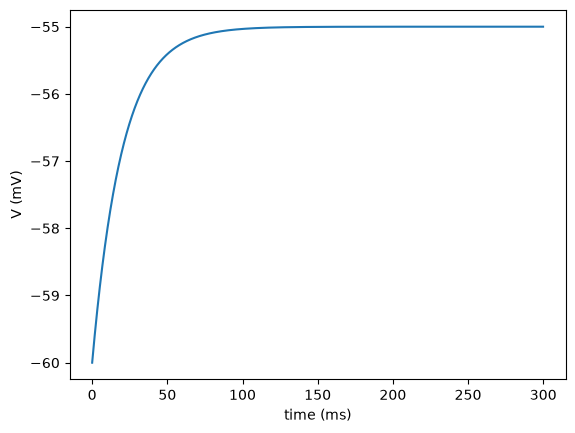

In [7]:
plt.plot(mon.t/ms, mon.V[0]/mV)
plt.xlabel("time (ms)")
plt.ylabel("V (mV)");

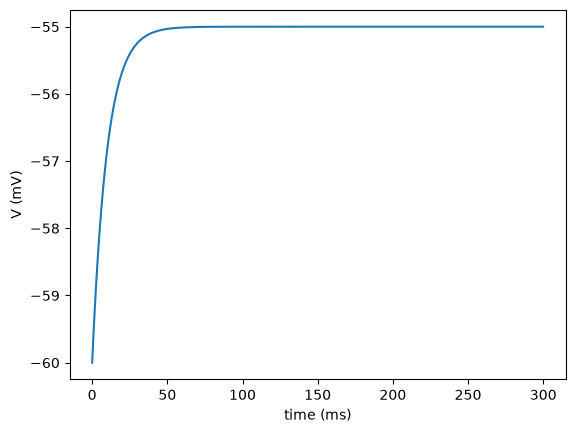

In [9]:
start_scope()
C = (0.5*ufarad*cm**-2) * area
neuron = NeuronGroup(1, lif_eqs, threshold="V>-50*mV", reset="V=-80*mV", refractory=5*ms, method='euler')
neuron.V = E_L
neuron.I_stim = 0.05*nA

mon = StateMonitor(neuron, "V", record=0)
run(300*ms)

plt.plot(mon.t/ms, mon.V[0]/mV)
plt.xlabel("time (ms)")
plt.ylabel("V (mV)");

It reaches the same steady-state value as before, but faster.

4. In the neuron model from the example code above: is there an upper limit to the neuron's firing rate, e.g. when receiving a very strong input current? If no, why not? If yes, what is the limit?

**SOLUTION**
Yes, the model has an absolute refractory period of 5ms, meaning that even for an extremely strong input current, it will only spike once every 5ms. This means its maximal firing rate is 200Hz.